In [1]:
%load_ext autoreload
%autoreload 2

import torch
import numpy as np
from botorch.models import MixedSingleTaskGP
from botorch.models.transforms.outcome import Standardize
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood
from smt.sampling_methods import LHS

from comcatalyst.xprs.xpr import Xpr
from comcatalyst.xprs.xpr_smt import XprSmt
from comcatalyst.xprs.xpr_botorch import XprBotorch, XprBotorchHyperparams
from comcatalyst.context.cases import case_01, case_02, case_03, case_03_bis_2d, case_04
from comcatalyst.xprs.visualizations import (
    plot_1d_ground_truth, plot_1d_gp_quant_by_qual, 
    plot_contour_quant_by_qual,
    plot_3d_quant_by_qual,
    plot_gp_at_iter,
    animate_gp_at_iters,
    plot_convergence
)

c:\Users\siyanasran\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [88]:
# context
case = case_03_bis_2d()

# hyperparameters
seed = 1
seed_ydoe_offset = 1000
n_init = 10
n_iter_bo = 20
acq_type = "EI"
gp_type = "polynomial"
num_fantasies = 8
beta = 2.0
num_restarts = 4
raw_samples = 128
sigma_noise = 0.1

In [67]:
# True max
x_true_max, y_true_max, X_grid, Y_grid = XprSmt.calc_true_max(
    fn_gp_objective=case.fn_gp_objective, 
    vars_metadata=case.vars_metadata, 
    z=case.z, 
    n_grid=1000
)


In [68]:
print(f"x_true_max = {case.vars_metadata.str_values(x_true_max)}")
print(f"y_true_max = {y_true_max:.12f}")

x_true_max = c1 = A / c2 = alpha / x1 = -0.0991 / x3 = 0.0490
y_true_max = 5.309929136279


In [ ]:
# plot true max contour
plot_contour_quant_by_qual(
    metric='fn',
    vars_metadata=case.vars_metadata,
    quant_to_variate_idx_1=2,
    quant_to_variate_idx_2=3,
    # quant_fixed_vals=[(4, 0.0505)],
    qual_filter=None,
    fn_gp_objective=case.fn_gp_objective,
    z=case.z,
    x_true_max=x_true_max,
    y_true_max=y_true_max,
    n_grid=30,
    n_cols=4,
    figsize=(11,8),
    fontsize=16,
    title=""
)

In [89]:
# LHS
x_init, _ = Xpr.calc_x_init_with_sampling_method(
    vars_metadata=case.vars_metadata,
    n_init=n_init,
    sampling_method=LHS,
    sampling_criterion="ese",
    seed=seed,
)

y_init = case.fn_gp_objective(
    vars_metadata=case.vars_metadata,
    x=x_init,
    z=case.z,
    sigma_noise=sigma_noise,
    rng=np.random.default_rng(seed + seed_ydoe_offset),
)

# EGO
res_ego = XprBotorch.run_ego(
    fn_gp_objective=case.fn_gp_objective,
    vars_metadata=case.vars_metadata,
    z=case.z,
    n_iter_bo=n_iter_bo,
    acq_type=acq_type,
    gp_type=gp_type,
    num_fantasies=num_fantasies,
    beta=beta,
    num_restarts=num_restarts,
    raw_samples=raw_samples,
    sigma_noise=sigma_noise,
    seed=seed,
    x_init=x_init,
    y_init=y_init,
)

In [90]:
# EGO results details
print(f"--- BO x_data ---\n{res_ego.x_data}")
print(f"\n--- BO y_data ---\n{res_ego.y_data}")
print(f"\n--- BO y_true_at_x_data ---\n{res_ego.y_true_at_x_data}")

print("\n--- Results ---")
print(" "*2 + f"x_opt = {case.vars_metadata.str_values(res_ego.x_opt)}")
print(" "*2 + f"y_opt = {res_ego.y_opt:.4f}")
print(" "*2 + f"y_true_at_x_opt = {res_ego.y_true_at_x_opt:.4f}")

--- BO x_data ---
[[ 3.          3.          0.56536507 -0.74753733]
 [ 0.          2.         -0.89008126  0.09438194]
 [ 0.          3.          0.17530742 -0.03607466]
 [ 2.          0.         -0.17041559  0.39273417]
 [ 3.          2.          0.87608485  0.57710405]
 [ 3.          0.          0.36101097 -0.40601492]
 [ 0.          1.         -0.75930895 -0.38753008]
 [ 1.          0.         -0.5678696   0.94505879]
 [ 2.          3.          0.6750294   0.66334763]
 [ 1.          3.         -0.30813282 -0.99448818]
 [ 2.          0.         -0.35033592 -0.08705858]
 [ 2.          0.         -0.60790701  1.        ]
 [ 0.          1.         -1.          1.        ]
 [ 1.          2.          1.          0.36213411]
 [ 0.          2.         -1.         -0.23191263]
 [ 0.          0.         -1.         -0.2402015 ]
 [ 0.          2.          1.          0.46126067]
 [ 0.          2.         -0.50726462 -0.19322425]
 [ 0.          2.         -0.53027829 -0.3812534 ]
 [ 0.        

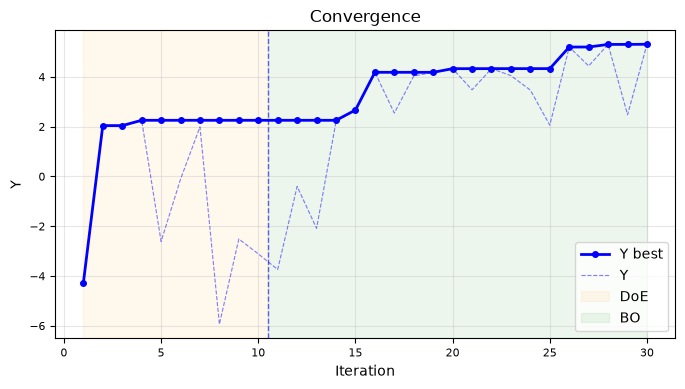

In [82]:
# plot convergence
plot_convergence(
    y_data=res_ego.y_true_at_x_data,
    n_init=n_init,
)

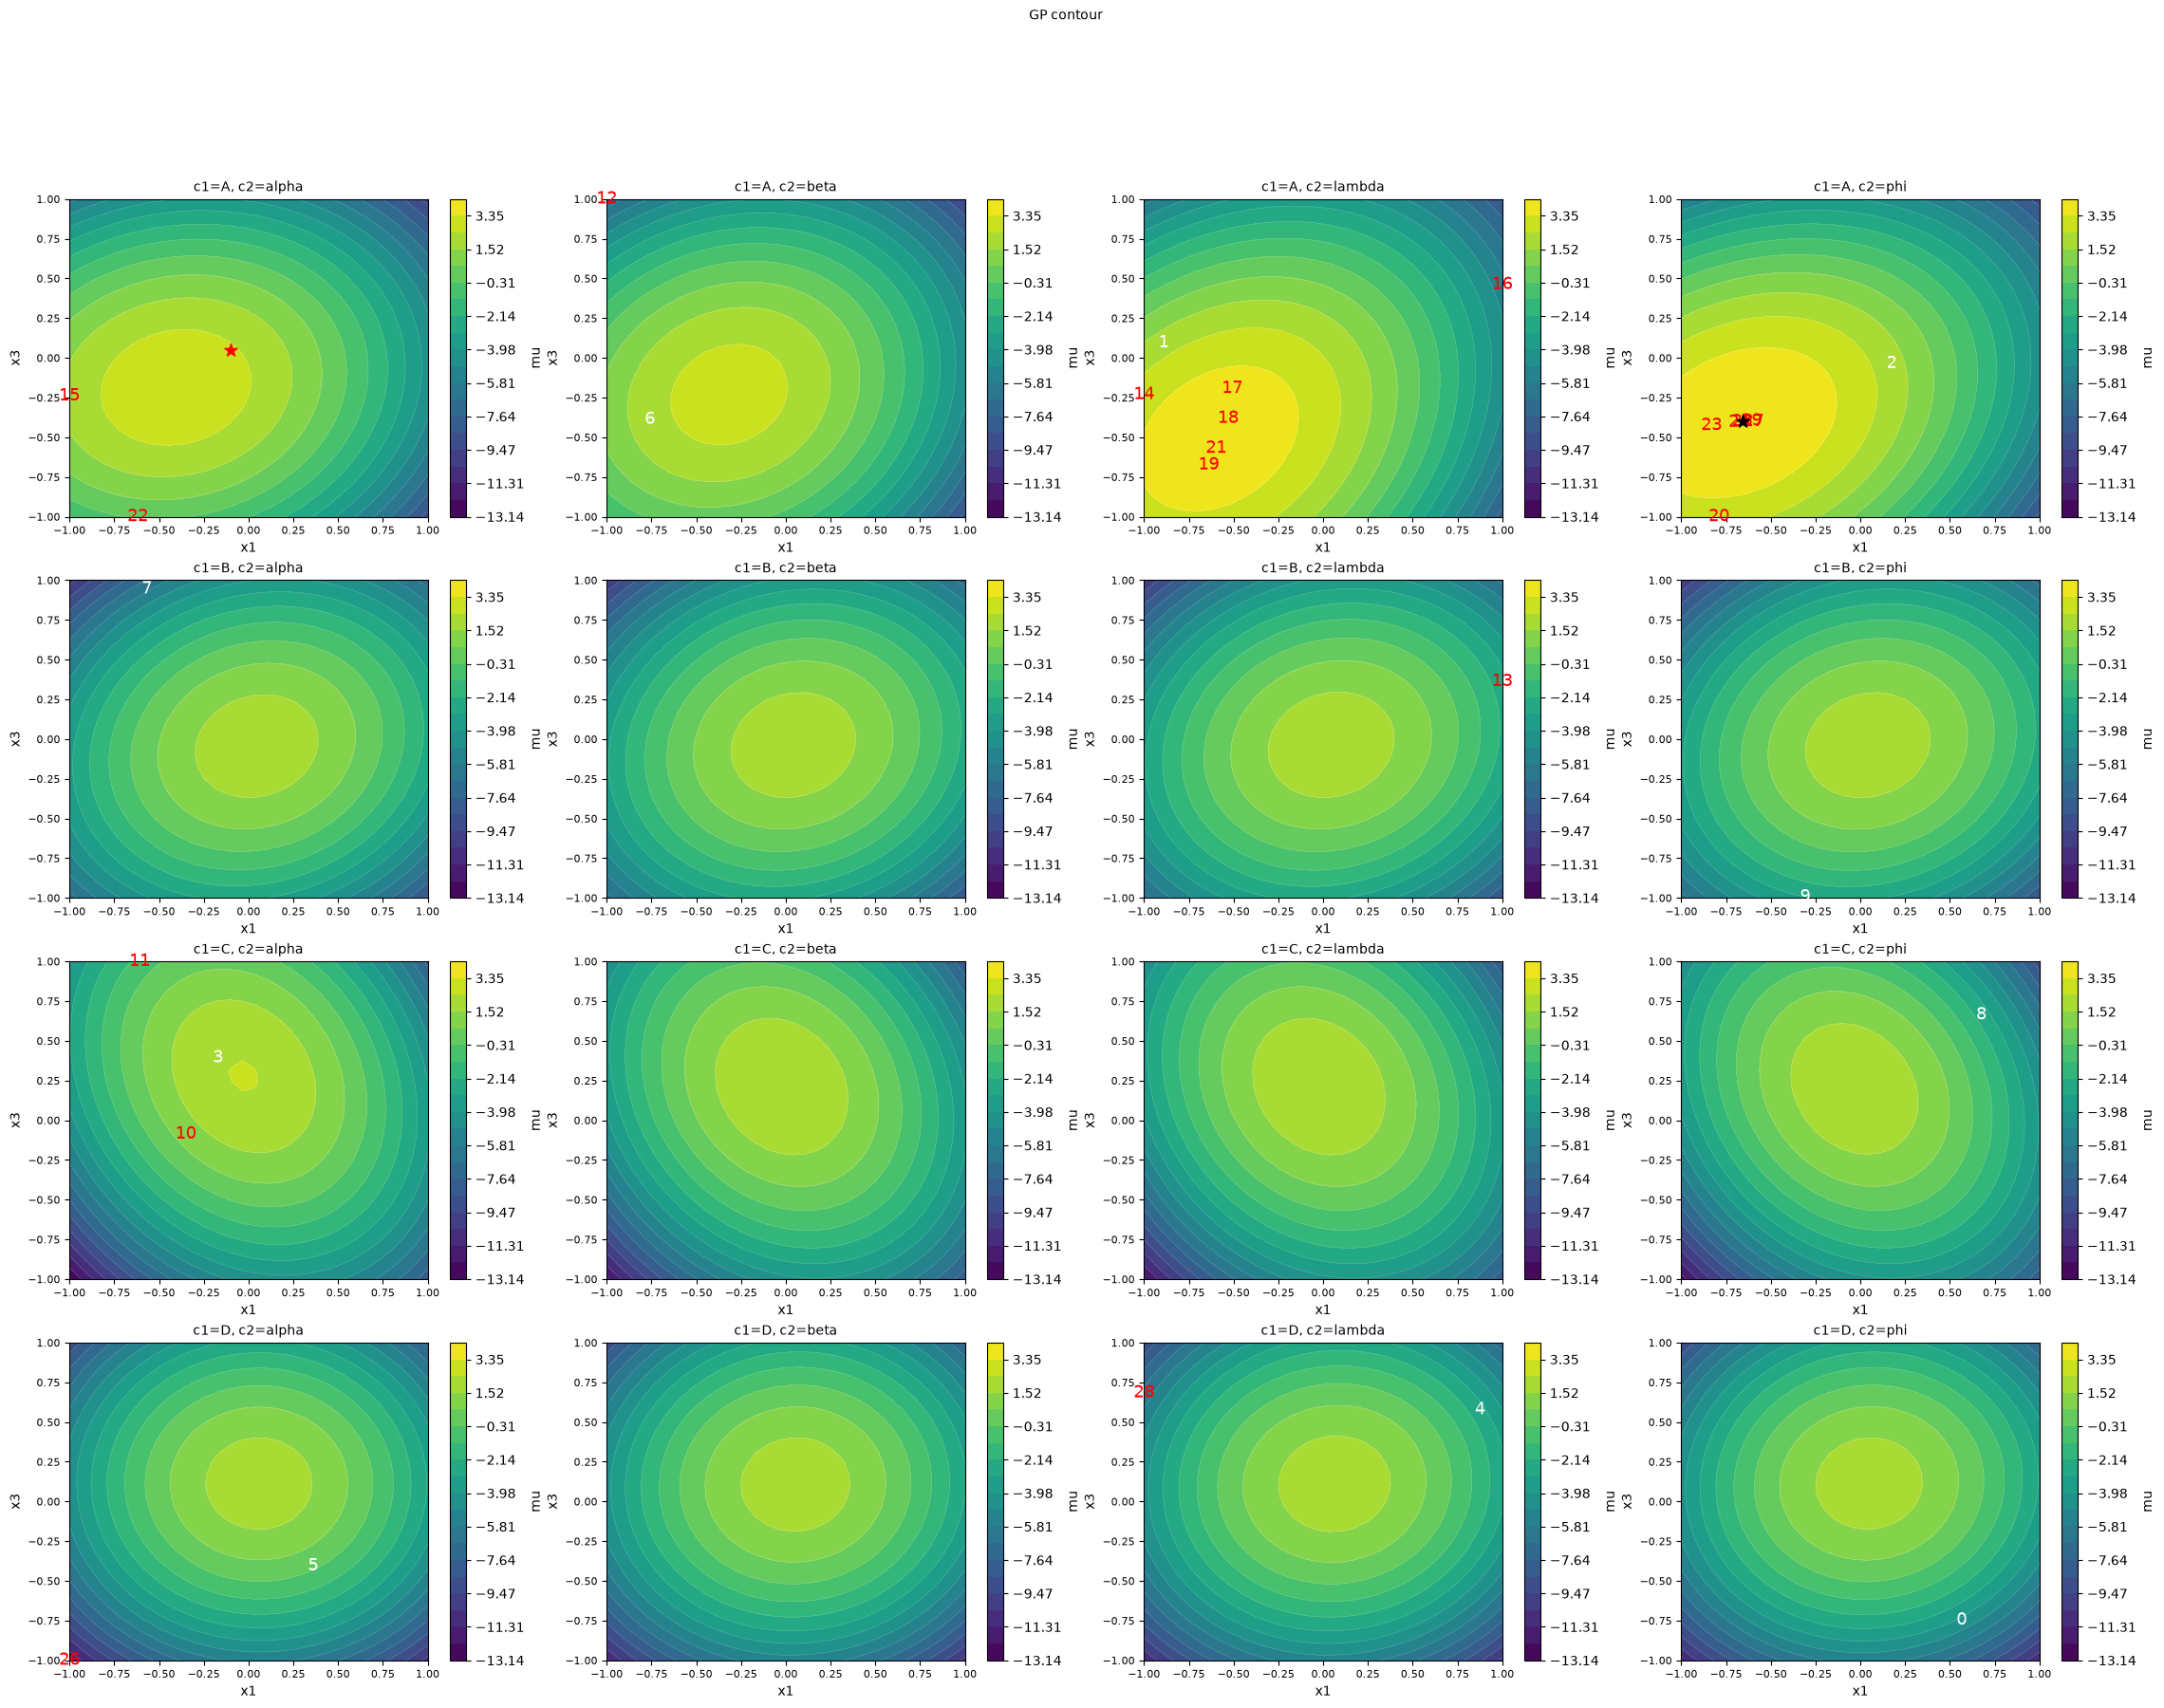

In [91]:
# plot GP contour level
plot_contour_quant_by_qual(
    metric='mu',
    vars_metadata=case.vars_metadata,
    quant_to_variate_idx_1=2,
    quant_to_variate_idx_2=3,
    #quant_fixed_vals=[(4, 0.051)],
    qual_filter=None,
    sm=res_ego.sm,
    reverse_optim=True,
    x_data=res_ego.x_data,
    y_data=res_ego.y_data,
    n_init=n_init,
    x_opt=res_ego.x_opt,
    y_opt=res_ego.y_opt,
    x_true_max=x_true_max,
    y_true_max=y_true_max,
    n_grid=30,
    n_cols=4,
    figsize=(7,5)
)

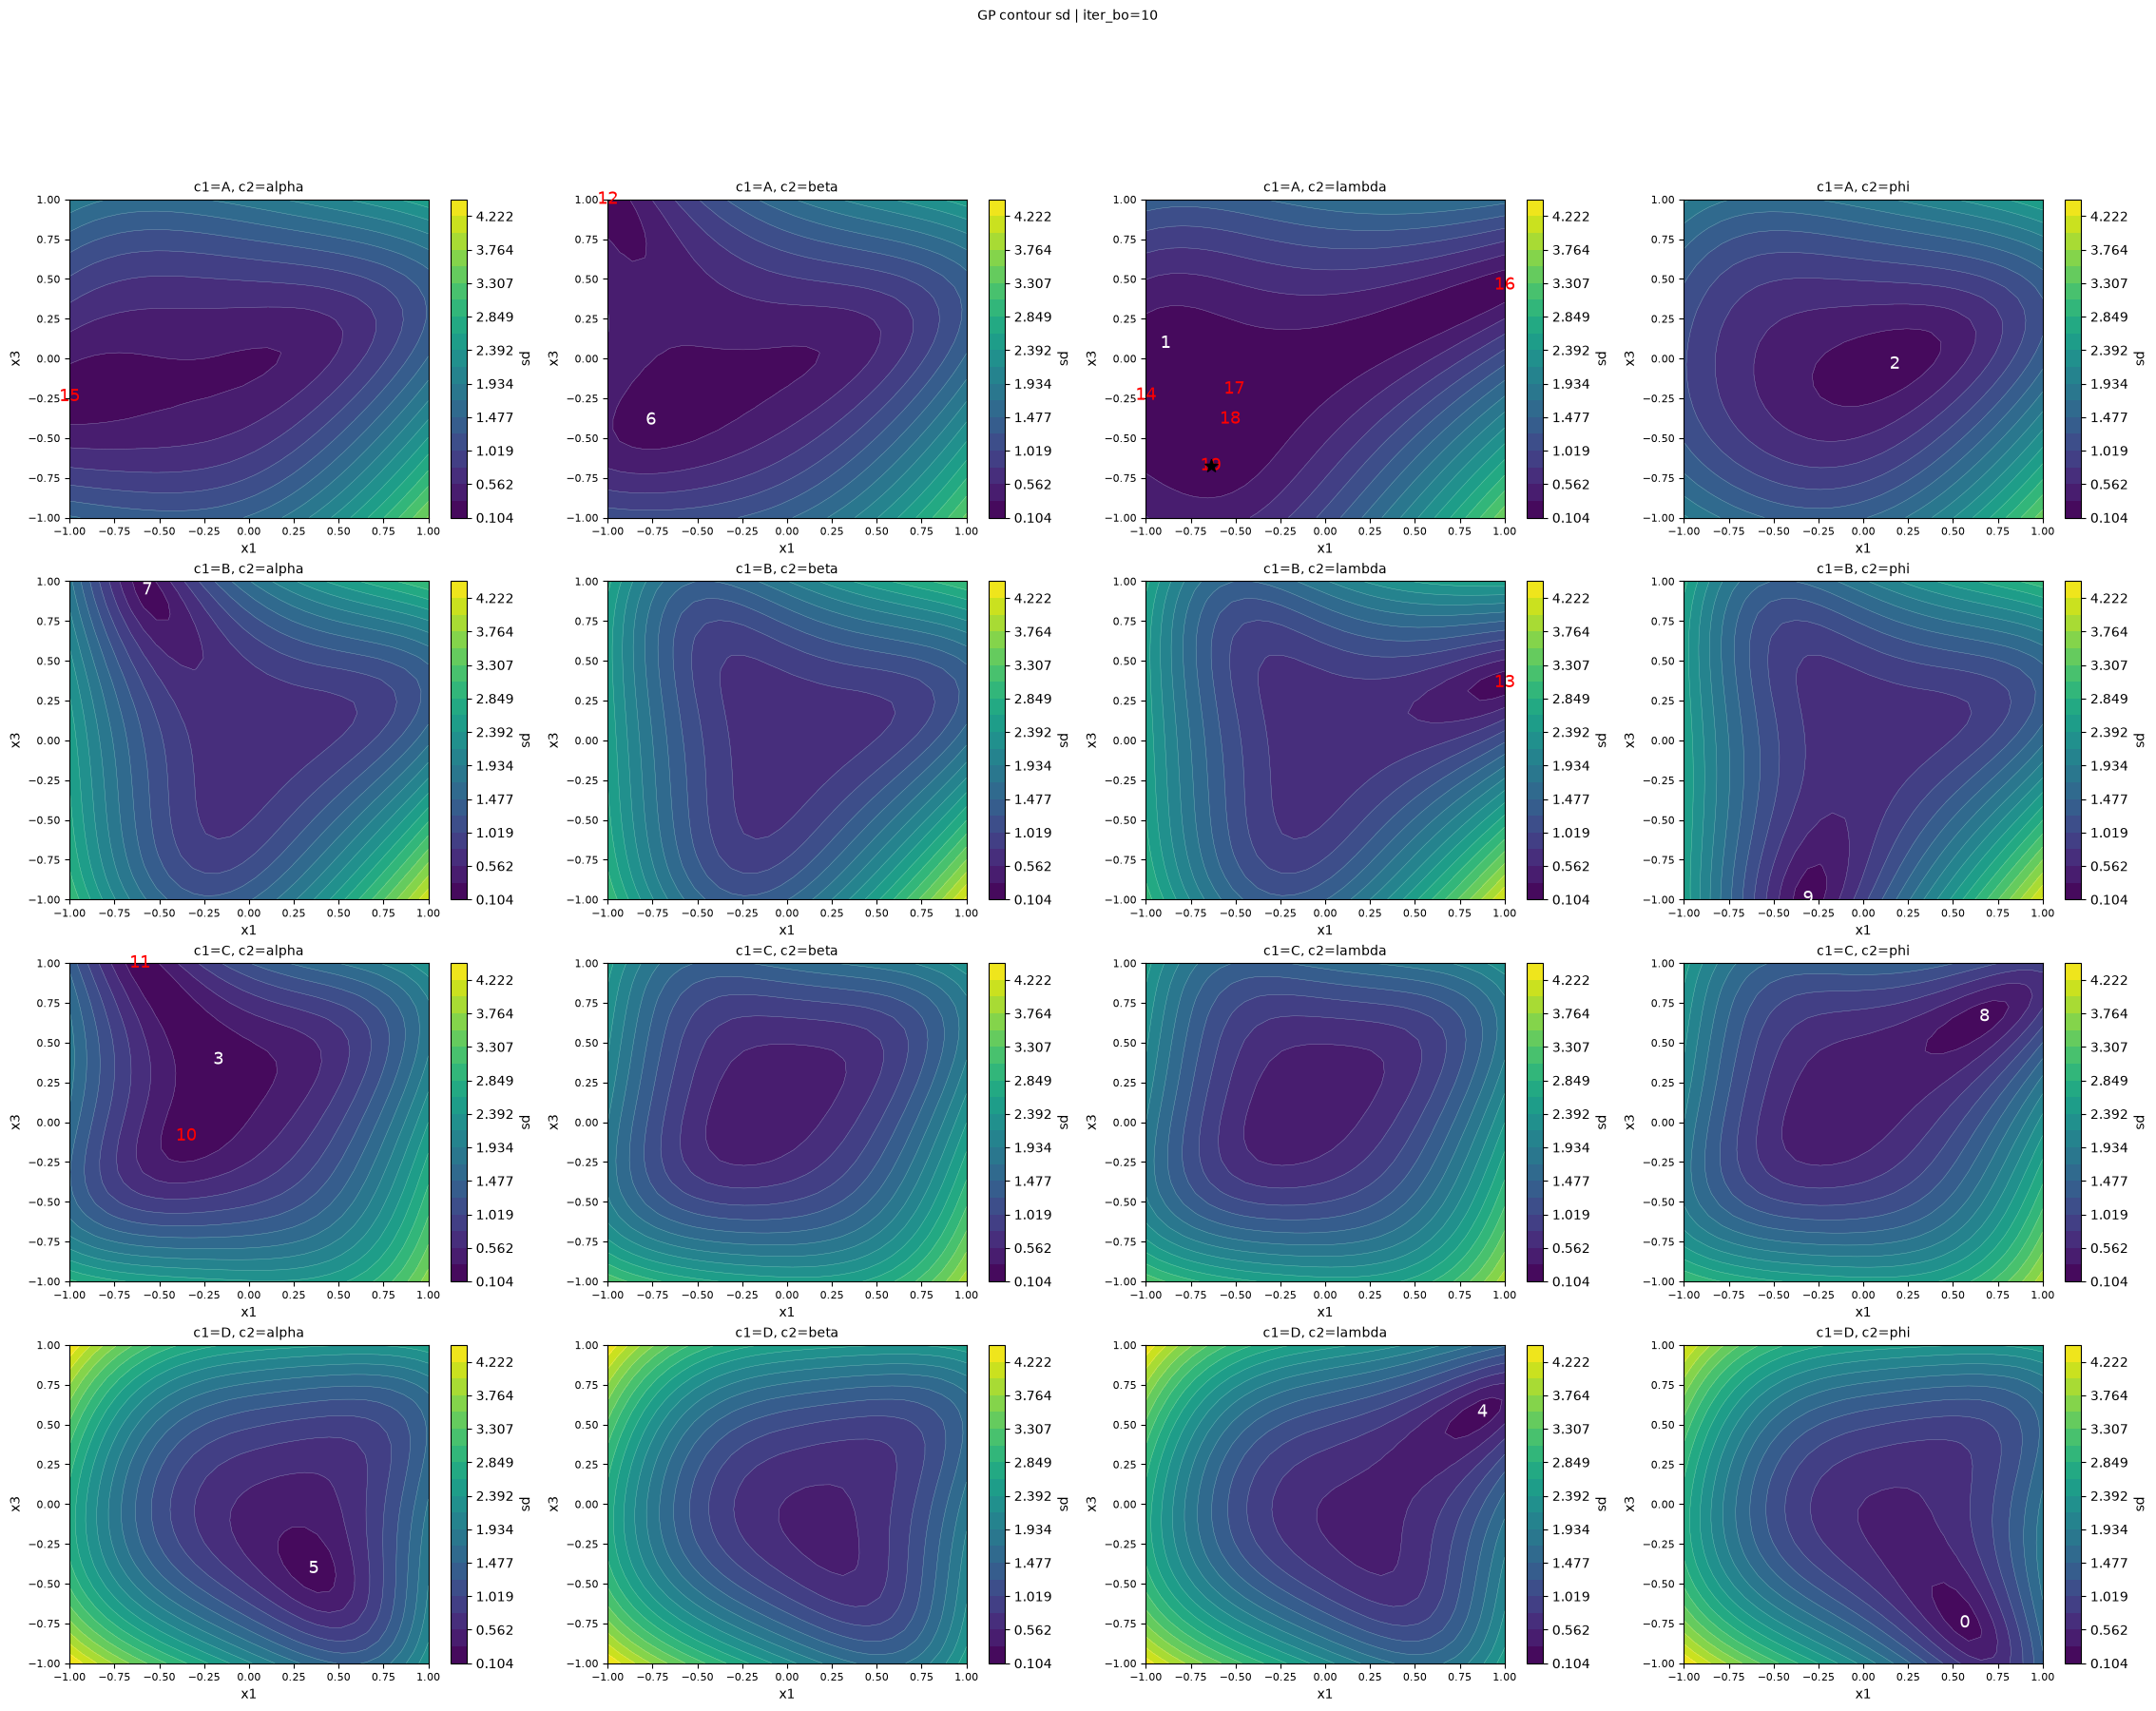

In [98]:
# plot contour gp at iter
plot_gp_at_iter(
    plot_type='contour',
    metric='sd',
    result_ego=res_ego,
    vars_metadata=case.vars_metadata,
    n_init=n_init,
    iter_bo=10,
    quant_to_variate_idx_1=2,
    quant_to_variate_idx_2=3,
    quant_fixed_vals=None,
    qual_filter=None,
    n_grid=30,
    n_cols=4,
    figsize=(7,5),
    title=None,
    save_path=None
)